# PROYECTO DATASET ESTUDIANTES

Este proyecto consta de cuatro bloques fundamentales:

1.- Análisis exploratorio del conjunto de datos

2.- Preprocesamiento de los datos

3.- Entrenamiento y validación del modelo de regresión

4.- Entrenamiento y validación del modelo de clasificación

Las variables objetivo serán:

- Para el modelo de regresión: nota_final
- Para el modelo de clasificación: aprobado

## 1. Análisis exploratorio del conjunto de datos

In [1]:
#Importación de librerias para e tratamiento de datos y visualización de los mismos.
import pandas as pd
import matplotlib.pyplot as plt

### 1.1 Análisis básicos de las variables del conjunto de datos

#### Carga de datos

In [2]:
#Carga del archivo de datos y visualización.
df = pd.read_csv("dataset_estudiantes.csv")
df.head()

,horas_estudio_semanal,nota_anterior,tasa_asistencia,horas_sueno,edad,nivel_dificultad,tiene_tutor,horario_estudio_preferido,estilo_aprendizaje,nota_final,aprobado
0,8.957476,48.830601,86.640182,6.675694,25,Fácil,Sí,Tarde,Lectura/Escritura,84.4,1
1,11.042524,80.825707,83.449655,4.616844,18,Difícil,No,Tarde,NaN,72.0,1
2,4.510776,90.383694,74.623607,7.755246,25,Fácil,No,Mañana,Lectura/Escritura,80.0,1
3,6.647213,81.878257,82.849841,8.592826,23,Fácil,No,NaN,Visual,78.2,1
4,1.000000,66.254179,54.539935,6.671840,21,Medio,No,NaN,Auditivo,66.0,1


#### Información básica del conjunto de datos: tamaño y tipología de variables

In [3]:
#Dimensiones del dataframe(df)
df.shape

(1000, 11)

In [4]:
#Información básicas de las variables (df)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 11 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   horas_estudio_semanal      1000 non-null   float64
 1   nota_anterior              1000 non-null   float64
 2   tasa_asistencia            1000 non-null   float64
 3   horas_sueno                850 non-null    float64
 4   edad                       1000 non-null   int64  
 5   nivel_dificultad           1000 non-null   str    
 6   tiene_tutor                1000 non-null   str    
 7   horario_estudio_preferido  900 non-null    str    
 8   estilo_aprendizaje         950 non-null    str    
 9   nota_final                 1000 non-null   float64
 10  aprobado                   1000 non-null   int64  
dtypes: float64(5), int64(2), str(4)
memory usage: 86.1 KB


#### Revisión de valores nulos y duplicados

In [5]:
#Número de valores nulos por variable (df)
df.isna().sum()

horas_estudio_semanal          0
nota_anterior                  0
tasa_asistencia                0
horas_sueno                  150
edad                           0
nivel_dificultad               0
tiene_tutor                    0
horario_estudio_preferido    100
estilo_aprendizaje            50
nota_final                     0
aprobado                       0
dtype: int64

In [6]:
#Revisión de duplicados (df)
df.duplicated().sum()

np.int64(0)

Se identifican 3 variables con valores nulos y no se encuentran duplicados en el conjunto de datos.

#### Valores estadísticos básicos de las variables numéricas

In [7]:
#Númer de valores, media, desviación estándar, mínimo, máximo y percentiles de las variables (df)
df.describe().round(2)

,horas_estudio_semanal,nota_anterior,tasa_asistencia,horas_sueno,edad,nota_final,aprobado
count,1000.00,1000.00,1000.00,850.00,1000.00,1000.00,1000.0
mean,10.07,69.89,73.99,7.01,23.53,71.44,0.9
std,4.85,14.69,18.20,1.44,3.48,9.56,0.3
min,1.00,30.00,20.00,4.00,18.00,30.00,0.0
25%,6.63,59.88,61.51,6.00,21.00,64.78,1.0
50%,10.00,70.00,75.00,7.02,24.00,71.40,1.0
75%,13.37,80.12,88.49,8.02,27.00,77.90,1.0
max,25.00,100.00,100.00,10.00,29.00,100.00,1.0


#### Análisis de las variables categóricas

In [8]:
#Revisión del número de estudiantes según el nivel de dificultad (df)
df["nivel_dificultad"].value_counts(dropna=False)

nivel_dificultad
Medio      504
Fácil      313
Difícil    183
Name: count, dtype: int64

In [9]:
#Revisión del número de estudiantes según si tienen tutor o no (df)
df["tiene_tutor"].value_counts(dropna=False)

tiene_tutor
No    597
Sí    403
Name: count, dtype: int64

In [10]:
#Revisión del número de estudiantes según el horario de estudio preferido (df)
df["horario_estudio_preferido"].value_counts(dropna=False)

horario_estudio_preferido
Noche     344
Tarde     337
Mañana    219
NaN       100
Name: count, dtype: int64

In [11]:
 #Revisión del número de estudiantes según el estilo de aprendizaje preferido (df)
df["estilo_aprendizaje"].value_counts(dropna=False)

estilo_aprendizaje
Visual               363
Auditivo             254
Kinestésico          178
Lectura/Escritura    155
NaN                   50
Name: count, dtype: int64

#### Análisis de variable objetivo: nota_final

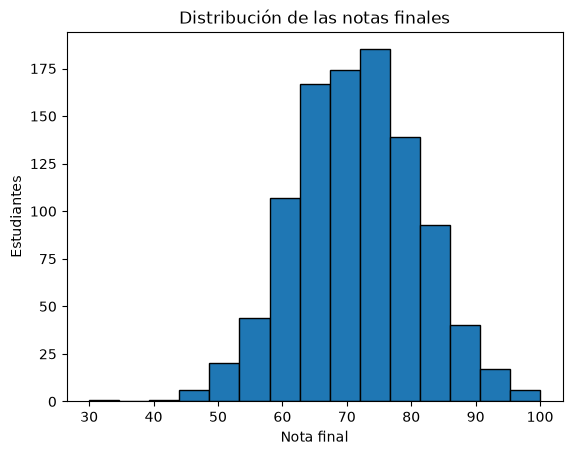

In [12]:
#Representación gráfica de la variable mediante histograma
plt.hist(df["nota_final"], bins=15, edgecolor="black")

plt.title("Distribución de las notas finales")
plt.xlabel("Nota final")
plt.ylabel("Estudiantes")

plt.show()

#### Análisis de variable objetivo: aprobado
Valores posibles: 0 (suspenso) y 1 (aprobado)

In [13]:
#Total de aprobados y suspenso sobre el total de estudiantes (df)
df["aprobado"].value_counts()

aprobado
1    898
0    102
Name: count, dtype: int64

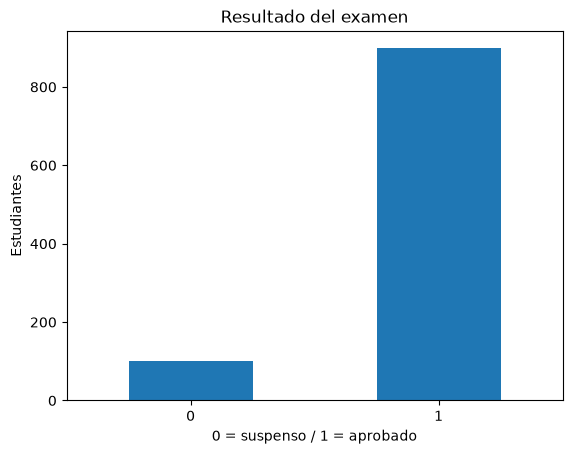

In [14]:
#Visualización de resultados mediante gráfico de barras
recuento = df["aprobado"].value_counts().sort_index()

recuento.plot(kind="bar")

plt.title("Resultado del examen")
plt.xlabel("0 = suspenso / 1 = aprobado")
plt.ylabel("Estudiantes")

plt.xticks(rotation=0)

plt.show()

### 1.2 Relaciones entre variables del conjunto de datos

#### 1.2.1 Relaciones entre las variables numéricas y la nota final

##### Relación entre las horas de estudio y la nota final

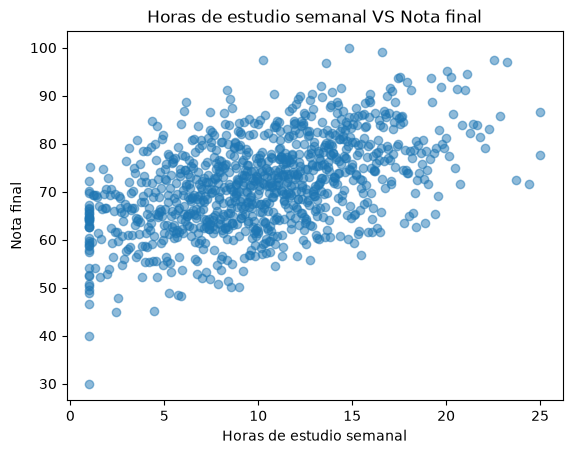

In [15]:
#Representamos la relación entre las horas de estudio frente a la nota final
plt.scatter(df["horas_estudio_semanal"], df["nota_final"], alpha=0.5)

plt.title("Horas de estudio semanal VS Nota final")
plt.xlabel("Horas de estudio semanal")
plt.ylabel("Nota final")

plt.show()

El gráfico de dispersión muestra una relación positiva entre las horas de estudio semanal y la nota final. A mayor número de horas, las notas tienden a ser más altas.

In [16]:
#Calculamos la correlación entre las horas de estudio semanal y la nota final
round(df["horas_estudio_semanal"].corr(df["nota_final"]), 4)

np.float64(0.5136)

La correlación de Pearson entre las horas de estudio semanal y la nota final es de aproximadamente 0,5136. Este valor indica que hay una relación moderada entre el número de horas de estudio y la nota final.

##### Relación entre la nota anterior y la nota final

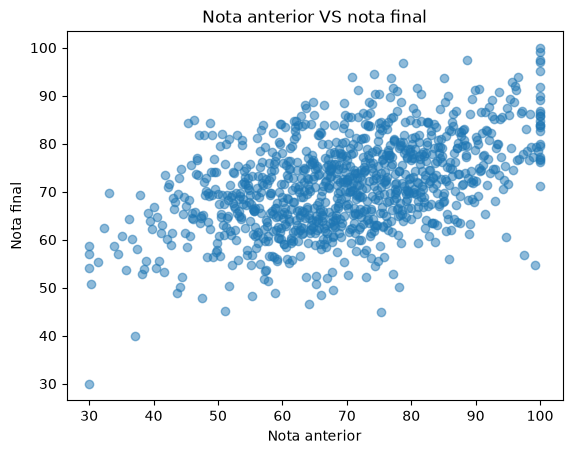

In [17]:
#Representamos la relación entre la nota anterior y la nota final
plt.scatter(df["nota_anterior"], df["nota_final"], alpha=0.5)

plt.title("Nota anterior VS nota final")
plt.xlabel("Nota anterior")
plt.ylabel("Nota final")

plt.show()

In [18]:
#Calculamos la correlación entre ambas notas
round(df["nota_anterior"].corr(df["nota_final"]), 4)

np.float64(0.4698)

Se observa una relación lineal positiva moderada entre la nota anterior y la nota final, con una correlación de aproximadamente 0,470. Los estudiantes con mejores notas anteriores tienden a obtener notas finales más altas.

##### Relación entre la tasa de asistencia y la nota final

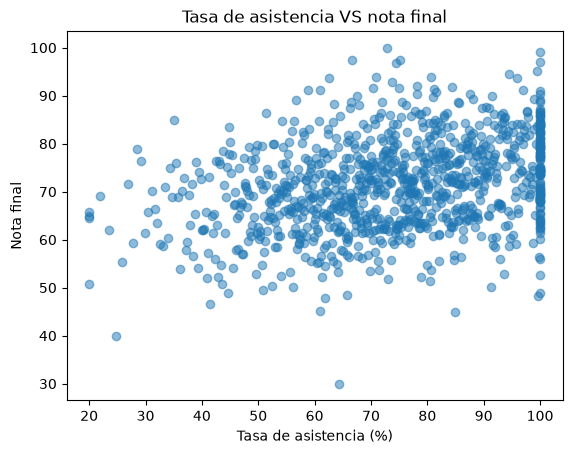

In [19]:
#Representamos la relación entre la tasa de asistencia y la nota final
plt.scatter(df["tasa_asistencia"], df["nota_final"], alpha=0.5)

plt.title("Tasa de asistencia VS nota final")
plt.xlabel("Tasa de asistencia (%)")
plt.ylabel("Nota final")

plt.show()

In [20]:
#Calculamos la correlación entre asistencia y nota final
round(df["tasa_asistencia"].corr(df["nota_final"]), 4)

np.float64(0.3168)

El gráfico muestra bastante dispersión, aunque hay cierta relación entre los estudiantes que obtienen mejores notas y su mayor asistencia a clase.

##### Resumen de relaciones de Pearson entre variables numéricas y la nota final

In [21]:
#Variables numéricas que vamos a comparar
variables_numericas = ["horas_estudio_semanal", "nota_anterior", "tasa_asistencia", "horas_sueno", "edad", "nota_final"]

#Calculamos todas sus correlaciones entre sí
correlaciones = df[variables_numericas].corr()

#Mostramos la correlación de cada variable con la nota final
correlaciones["nota_final"].round(3)

horas_estudio_semanal    0.514
nota_anterior            0.470
tasa_asistencia          0.317
horas_sueno              0.075
edad                    -0.012
nota_final               1.000
Name: nota_final, dtype: float64

En resumen sobre las variables analizadas, las horas de estudio, la nota anterior y la tasa de asistencia, tienen un relación positiva moderada o ligera. Por su parte, la horas de sueño y la edad, no muestran prácticamente relación con la nota final.

### 1.2.2 Relaciones entre las variables categóricas y la nota final

#### Relación entre tener tutor y la nota final

In [22]:
#Calculamos la nota final media de todos los estudiantes
round(df["nota_final"].mean(), 2)

np.float64(71.44)

In [23]:
#Calculamos la nota final media en función del resultado de la catergoría "tiene_tutor"
medias_tutor = round(df.groupby("tiene_tutor")["nota_final"].mean(), 2)
medias_tutor

tiene_tutor
No    68.84
Sí    75.29
Name: nota_final, dtype: float64

Se observa una mayor nota media de los estudiantes que tienen tutor frente a los que no lo tienen.

#### Relación entre el nivel de dificultad del alumno para el estudio y la nota final

In [24]:
#Calculamos la nota final media para categoría del nivel de dificultad de estudio
medias_dificultad = round(df.groupby("nivel_dificultad")["nota_final"].mean(), 2)
medias_dificultad

nivel_dificultad
Difícil    69.48
Fácil      72.50
Medio      71.49
Name: nota_final, dtype: float64

Las diferencias de nota final media según el nivel de dificultad son muy ligeras.

#### Relación entre el horario de estudio preferido y la nota final

In [25]:
#Calculamos la nota final media para cada horario de estudio
medias_horario = round(df.groupby("horario_estudio_preferido")["nota_final"].mean(), 2)
medias_horario

horario_estudio_preferido
Mañana    71.60
Noche     70.81
Tarde     71.71
Name: nota_final, dtype: float64

Las diferencias de nota final media según el horario de estudio son muy ligeras.

#### Relación entre el estilo de aprendizaje preferido y la nota final

In [26]:
#Calculamos la nota final media para cada estilo de aprendizaje
medias_estilo = round(df.groupby("estilo_aprendizaje")["nota_final"].mean(), 2)
medias_estilo

estilo_aprendizaje
Auditivo             71.82
Kinestésico          72.53
Lectura/Escritura    72.59
Visual               70.53
Name: nota_final, dtype: float64

Las notas finales medias de los distintos estilos de aprendizaje son muy similares y próximas a la media global.

### 1.2.3 Relaciones entre las algunas variables (categóricas y numéricas) y aprobar

#### Relación entre tener tutor y aprobar

In [27]:
#Calculamos el porcentaje de aprobados según si tienen tutor o no
proporcion_aprobados_tutor = df.groupby("tiene_tutor")["aprobado"].mean()
porcentaje_aprobados_tutor = round(proporcion_aprobados_tutor * 100, 2)
porcentaje_aprobados_tutor

tiene_tutor
No    85.76
Sí    95.78
Name: aprobado, dtype: float64

Se observa que los estudiantes con tutor, obtienen un mayor porcentaje de aprobados.

#### Relación entre el número de horas de estudio y aprobar

In [28]:
#Calculamos las horas de estudio medias de suspensos y aprobados
medias_estudio_resultado = round(df.groupby("aprobado")["horas_estudio_semanal"].mean(), 2)
medias_estudio_resultado

aprobado
0     5.86
1    10.55
Name: horas_estudio_semanal, dtype: float64

Existe un clara diferencia (cercana al doble de horas de estudio) entre los estudiantes que aprueban el examen y los que no.

#### Relación entre la nota del examen anterior y aprobar

In [29]:
#Calculamos la nota anterior media de suspensos y aprobados
medias_nota_anterior = round(df.groupby("aprobado")["nota_anterior"].mean(), 2)
medias_nota_anterior

aprobado
0    58.10
1    71.22
Name: nota_anterior, dtype: float64

Existe una clara diferencia en la nota media en el examen anterior, entre los estudiantes que aprueban y suspenden este último.

#### Relación entre la tasa de asistencia y aprobar

In [30]:
#Calculamos la asistencia media en función del resultado del examen
medias_asistencia_resultado = round(df.groupby("aprobado")["tasa_asistencia"].mean(), 2)
medias_asistencia_resultado

aprobado
0    62.97
1    75.24
Name: tasa_asistencia, dtype: float64

También se comprueba una mayor tasa de asistencia a clase entre los estudiantes que aprueban frente a los que no lo hacen.

### 1.2.4 Revisión de posibles valores atípicos

#### Horas de estudio semanal

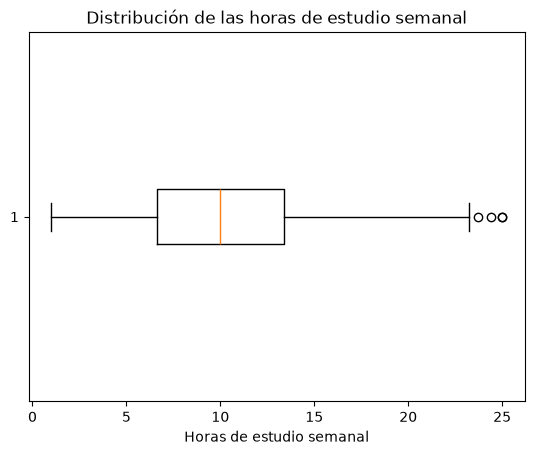

In [31]:
#Representamos las horas de estudio con un diagrama de caja
plt.boxplot(df["horas_estudio_semanal"], orientation="horizontal")

plt.title("Distribución de las horas de estudio semanal")
plt.xlabel("Horas de estudio semanal")

plt.show()

El diagrama muestra outliers en la parte alta de horas. Estos valores fuera de los bigotes se consideran factibles, aunque sean atípicos.

#### Horas de sueño diarias

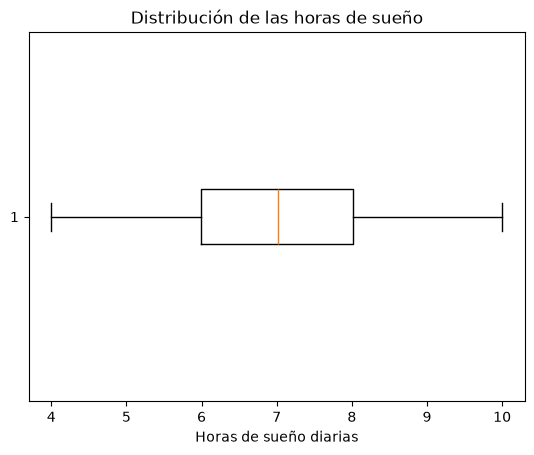

In [32]:
#Seleccionamos todos los registros que tienen dato de horas de sueño
sueno_sin_nulos = df["horas_sueno"].dropna()

#Representamos las horas de sueño con un diagrama de caja
plt.boxplot(sueno_sin_nulos, orientation="horizontal")

plt.title("Distribución de las horas de sueño")
plt.xlabel("Horas de sueño diarias")

plt.show()

El diagrama no muestra valores atípicos.

#### Tasa de asistencia

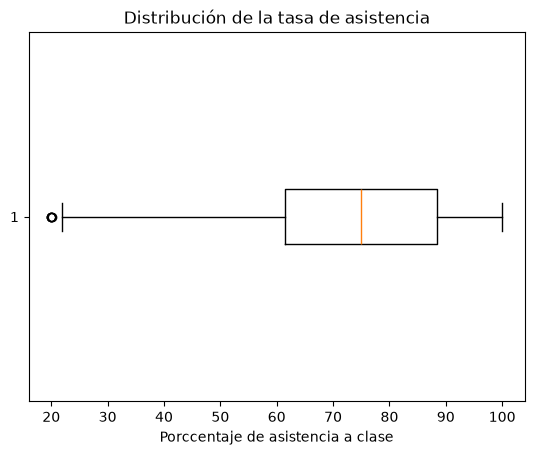

In [33]:
#Representamos la tasa de asistencia con un diagrama de caja
plt.boxplot(df["tasa_asistencia"], orientation="horizontal")

plt.title("Distribución de la tasa de asistencia")
plt.xlabel("Porccentaje de asistencia a clase")

plt.show()

El diagrama de caja muestra un posible valor atípico en la parte baja de la asistencia. Aunque atípico, está dentro del rango válido.

#### Nota anterior

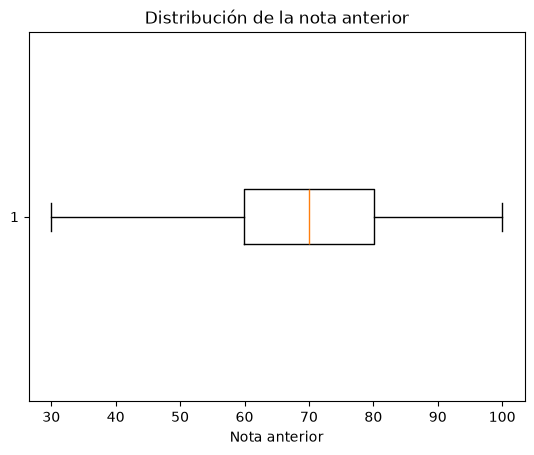

In [34]:
#Representamos la nota del examen anterior con un diagrama de caja
plt.boxplot(df["nota_anterior"], orientation="horizontal")

plt.title("Distribución de la nota anterior")
plt.xlabel("Nota anterior")

plt.show()

El diagrama no muestra valores atípicos.

#### Edades de los alumnos

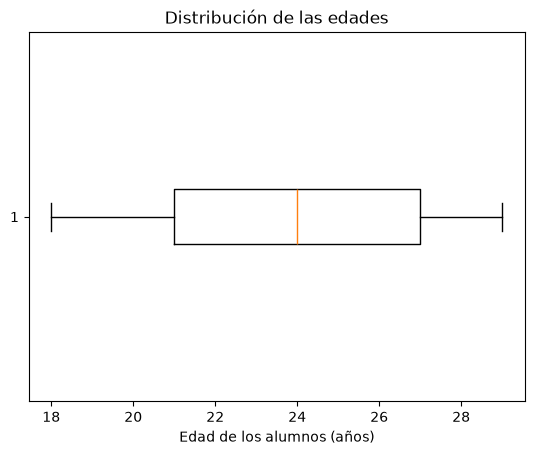

In [35]:
#Representamos las edades de los alumnos con un diagrama de caja
plt.boxplot(df["edad"], orientation="horizontal")

plt.title("Distribución de las edades")
plt.xlabel("Edad de los alumnos (años)")

plt.show()

El diagrama no muestra valores atípicos.

#### Nota final

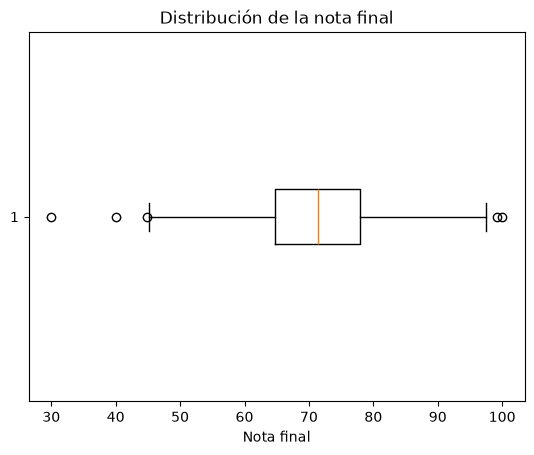

In [36]:
#Representamos la distribución de la nota final
plt.boxplot(df["nota_final"], orientation="horizontal")

plt.title("Distribución de la nota final")
plt.xlabel("Nota final")

plt.show()

En la nota final se observan valores atípicos tanto en el extremo inferior como en el superior. Estos valores están dentro del rango de 0 a 100 por lo que no se consideran erróneos.

### 1.2.5 Conclusiones del análisis exploratorio

- El dataset tiene un total de 1.000 registros, 9 variables de entrada y 2 variables objetivo. No se han encontrado filas duplicadas.

- Existen variables con registros sin dato: horas_sueno (15 %), horario_estudio_preferido (10 %) y estilo_aprendizaje (5 %).

- Las horas de estudio semanal, la nota anterior y la asistencia presentan relaciones lineales positivas con la nota final.

- Los estudiantes con tutor consiguen una nota media y un porcentaje de aprobados mayores. Las comparaciones por nivel de dificultad, horario y estilo de aprendizaje no muestran grandes diferencias en las notas medias.

- Los aprobados tienen, de media, más horas de estudio, mejores notas anteriores y mayor asistencia que los suspensos.

- Se han encontrado valores atípicos en diferentes variables, pero se identifican como factibles por lo que se conservan.

## 2. Preprocesamiento de los datos

### 2.1 Separación de las variables de entrada y las variables objetivo (nota_final para regresión y aprobado para clasificación)

In [37]:
#Creación del dataframe con los valores de entrada al modelo
X = df.drop(columns=["nota_final", "aprobado"])
X.head()

,horas_estudio_semanal,nota_anterior,tasa_asistencia,horas_sueno,edad,nivel_dificultad,tiene_tutor,horario_estudio_preferido,estilo_aprendizaje
0,8.957476,48.830601,86.640182,6.675694,25,Fácil,Sí,Tarde,Lectura/Escritura
1,11.042524,80.825707,83.449655,4.616844,18,Difícil,No,Tarde,NaN
2,4.510776,90.383694,74.623607,7.755246,25,Fácil,No,Mañana,Lectura/Escritura
3,6.647213,81.878257,82.849841,8.592826,23,Fácil,No,NaN,Visual
4,1.000000,66.254179,54.539935,6.671840,21,Medio,No,NaN,Auditivo


In [38]:
#Creación del dataframe con la variable objetivo para el modelo de regresión
y_regresion = df["nota_final"]
y_regresion.head()

0    84.4
1    72.0
2    80.0
3    78.2
4    66.0
Name: nota_final, dtype: float64

In [39]:
#Creación del dataframe con la variable objetivo para el modelo de clasificación
y_clasificacion = df["aprobado"]
y_clasificacion.head()

0    1
1    1
2    1
3    1
4    1
Name: aprobado, dtype: int64

In [40]:
X.shape

(1000, 9)

In [41]:
y_regresion.shape

(1000,)

In [42]:
y_clasificacion.shape

(1000,)

### 2.2 Separación de los datos para entrenamiento y prueba del modelo

In [43]:
#Función que permite la división de los datos en conjuntos de entrenamiento y prueba para regresión y clasificación
from sklearn.model_selection import train_test_split

In [44]:
#Dividimos los datos entre entrenamiento (80%) y prueba (20%)
X_train, X_test, y_reg_train, y_reg_test, y_clas_train, y_clas_test = train_test_split(
    X,
    y_regresion,
    y_clasificacion,
    test_size=0.2,
    random_state=42,
    stratify=y_clasificacion
)

In [45]:
X_train.shape

(800, 9)

In [46]:
X_test.shape

(200, 9)

### 2.3 Tratamiento de valores nulos

In [47]:
X_train_preparado = X_train.copy()
X_test_preparado = X_test.copy()

In [106]:
#Calculamos la mediana de la variable horas_sueno en los datos de entrenamiento
mediana_sueno = round(X_train["horas_sueno"].median(),2)
mediana_sueno

np.float64(7.03)

In [49]:
#Sustituimos los valores nulos en los datos de entrenamiento por la mediana de los propios datos de entrenamiento
X_train_preparado["horas_sueno"] = X_train_preparado["horas_sueno"].fillna(mediana_sueno)

In [50]:
#Sustituimos los valores nulos en los datos de prueba por la mediana de los datos de entrenamiento
X_test_preparado["horas_sueno"] = X_test_preparado["horas_sueno"].fillna(mediana_sueno)

In [51]:
X_train_preparado["horas_sueno"].isna().sum()

np.int64(0)

In [52]:
X_test_preparado["horas_sueno"].isna().sum()

np.int64(0)

### 2.4 Codificación numérica de las variables categóricas

#### Conversión de las variables "tiene_tutor" y "nivel_dificultad"
- La variable tiene_tutor la codificamos con 0 (no tiene tutor) o 1 (sí tiene tutor).
- La variable nivel_dificultad la codificamos de 0 a 2 siguiendo un orden de menor a mayor dificultad.

In [53]:
#Convertimos las respuestas de texto en números
equivalencias_tutor = {"No": 0, "Sí": 1}
X_train_preparado["tiene_tutor"] = X_train["tiene_tutor"].map(equivalencias_tutor)
X_test_preparado["tiene_tutor"] = X_test["tiene_tutor"].map(equivalencias_tutor)

In [54]:
X_train_preparado["tiene_tutor"].value_counts(dropna=False)

tiene_tutor
0    475
1    325
Name: count, dtype: int64

In [55]:
X_test_preparado["tiene_tutor"].value_counts(dropna=False)

tiene_tutor
0    122
1     78
Name: count, dtype: int64

In [56]:
#Convertimos el texto de los niveles de dificultad en valores numéricos
equivalencias_dificultad = {"Fácil": 0, "Medio": 1, "Difícil": 2}
X_train_preparado["nivel_dificultad"] = X_train["nivel_dificultad"].map(equivalencias_dificultad)
X_test_preparado["nivel_dificultad"] = X_test["nivel_dificultad"].map(equivalencias_dificultad)

In [57]:
X_train_preparado["nivel_dificultad"].value_counts(dropna=False)

nivel_dificultad
1    403
0    251
2    146
Name: count, dtype: int64

In [58]:
X_test_preparado["nivel_dificultad"].value_counts(dropna=False)

nivel_dificultad
1    101
0     62
2     37
Name: count, dtype: int64

#### Conversión de la variable "horario_estudio_preferido"
Lo que hemos buscado con esta codificación es no dar mayor peso a ninguno de los horarios de estudio, si no, únicamente indicar si se ha elegido un horario u otro.

In [59]:
#Completamos todos los campos nulos de la variable de entrenamiento con el valor "Desconocido"
horarios_train = X_train_preparado["horario_estudio_preferido"].fillna("Desconocido")

#Creamos un dataframe cuyo índice es el código de estudiante y añadimos cuatros columunas según la categorización del horario de estudio
horarios_train_codificados = pd.DataFrame(index=horarios_train.index)
horarios_train_codificados["horario_Mañana"] = 0
horarios_train_codificados["horario_Tarde"] = 0
horarios_train_codificados["horario_Noche"] = 0
horarios_train_codificados["horario_Desconocido"] = 0

In [60]:
#Se marca con 1 el horario correspondiente a cada código de estudiante
horarios_train_codificados.loc[horarios_train == "Mañana", "horario_Mañana"] = 1
horarios_train_codificados.loc[horarios_train == "Tarde", "horario_Tarde"] = 1
horarios_train_codificados.loc[horarios_train == "Noche", "horario_Noche"] = 1
horarios_train_codificados.loc[horarios_train == "Desconocido", "horario_Desconocido"] = 1
horarios_train_codificados.head()

,horario_Mañana,horario_Tarde,horario_Noche,horario_Desconocido
206,0,1,0,0
847,0,1,0,0
667,1,0,0,0
670,0,1,0,0
33,0,1,0,0


In [61]:
#Comprobación final del total de horarios codificados en el dataframe de entrenamiento
suma_horarios = horarios_train_codificados.sum(axis=1)
suma_horarios.value_counts()

1    800
Name: count, dtype: int64

In [62]:
#Este segundo bloque de código realiza el mismo proceso anterior pero ahora sobre los de datos de prueba
horarios_test = X_test_preparado["horario_estudio_preferido"].fillna("Desconocido")

horarios_test_codificados = pd.DataFrame(index=horarios_test.index)
horarios_test_codificados["horario_Mañana"] = 0
horarios_test_codificados["horario_Tarde"] = 0
horarios_test_codificados["horario_Noche"] = 0
horarios_test_codificados["horario_Desconocido"] = 0

horarios_test_codificados.loc[horarios_test == "Mañana", "horario_Mañana"] = 1
horarios_test_codificados.loc[horarios_test == "Tarde", "horario_Tarde"] = 1
horarios_test_codificados.loc[horarios_test == "Noche", "horario_Noche"] = 1
horarios_test_codificados.loc[horarios_test == "Desconocido", "horario_Desconocido"] = 1

suma_horarios_test = horarios_test_codificados.sum(axis=1)
suma_horarios_test.value_counts()

1    200
Name: count, dtype: int64

In [63]:
#Eliminamos la columna original de horario de estudio preferido y unimos las codificadas, tanto en los datos de entrenamiento como en los de prueba
X_train_preparado = X_train_preparado.drop(columns=["horario_estudio_preferido"])
X_train_preparado = pd.concat([X_train_preparado, horarios_train_codificados],axis=1)

X_test_preparado = X_test_preparado.drop(columns=["horario_estudio_preferido"])
X_test_preparado = pd.concat([X_test_preparado, horarios_test_codificados],axis=1)

In [64]:
X_train_preparado.shape

(800, 12)

In [65]:
X_test_preparado.shape

(200, 12)

#### Codificación de la variable  "estilo_aprendizaje"

Al igual que en la codificación de la variable "horario_estudio_preferido", se busca no dar un peso mayor a ninguna de las categorías y simplemente indicar cuál es la activa para cada código de estudiante.

In [66]:
#Completamos todos los campos nulos de la variable de entrenamiento con el valor "Desconocido"
estilos_train = X_train_preparado["estilo_aprendizaje"].fillna("Desconocido")

#Creamos un dataframe cuyo índice es el código de estudiante y añadimos cuatros columunas según la categorización del estilo de aprendizaje
estilos_train_codificados = pd.DataFrame(index=estilos_train.index)
estilos_train_codificados["estilo_Visual"] = 0
estilos_train_codificados["estilo_Auditivo"] = 0
estilos_train_codificados["estilo_Kinestesico"] = 0
estilos_train_codificados["estilo_Lectura_Escritura"] = 0
estilos_train_codificados["estilo_Desconocido"] = 0

In [67]:
#Se marca con 1 el estilo de aprendizaje correspondiente a cada código de estudiante
estilos_train_codificados.loc[estilos_train == "Visual", "estilo_Visual"] = 1
estilos_train_codificados.loc[estilos_train == "Auditivo", "estilo_Auditivo"] = 1
estilos_train_codificados.loc[estilos_train == "Kinestésico", "estilo_Kinestesico"] = 1
estilos_train_codificados.loc[estilos_train == "Lectura/Escritura", "estilo_Lectura_Escritura"] = 1
estilos_train_codificados.loc[estilos_train == "Desconocido", "estilo_Desconocido"] = 1

In [68]:
#Comprobación final del total de estilos codificados en el dataframe de entrenamiento
suma_estilos_train = estilos_train_codificados.sum(axis=1)
suma_estilos_train.value_counts()

1    800
Name: count, dtype: int64

In [69]:
#Este segundo bloque de código realiza el mismo proceso anterior pero ahora sobre los de datos de prueba
estilos_test = X_test_preparado["estilo_aprendizaje"].fillna("Desconocido")

estilos_test_codificados = pd.DataFrame(index=estilos_test.index)
estilos_test_codificados["estilo_Visual"] = 0
estilos_test_codificados["estilo_Auditivo"] = 0
estilos_test_codificados["estilo_Kinestesico"] = 0
estilos_test_codificados["estilo_Lectura_Escritura"] = 0
estilos_test_codificados["estilo_Desconocido"] = 0

estilos_test_codificados.loc[estilos_test == "Visual", "estilo_Visual"] = 1
estilos_test_codificados.loc[estilos_test == "Auditivo", "estilo_Auditivo"] = 1
estilos_test_codificados.loc[estilos_test == "Kinestésico", "estilo_Kinestesico"] = 1
estilos_test_codificados.loc[estilos_test == "Lectura/Escritura", "estilo_Lectura_Escritura"] = 1
estilos_test_codificados.loc[estilos_test == "Desconocido", "estilo_Desconocido"] = 1

suma_estilos_test = estilos_test_codificados.sum(axis=1)
suma_estilos_test.value_counts()

1    200
Name: count, dtype: int64

In [70]:
#Eliminamos la columna original de estilo de aprendizaje y unimos las codificadas, tanto en los datos de entrenamiento como en los de prueba
X_train_preparado = X_train_preparado.drop(columns=["estilo_aprendizaje"])
X_train_preparado = pd.concat([X_train_preparado, estilos_train_codificados],axis=1)

X_test_preparado = X_test_preparado.drop(columns=["estilo_aprendizaje"])
X_test_preparado = pd.concat([X_test_preparado, estilos_test_codificados],axis=1)

In [71]:
X_train_preparado.shape

(800, 16)

In [72]:
X_test_preparado.shape

(200, 16)

### 2.5 Comprobación de los datos de entrenamiento y prueba

#### Comprobaciones generales

In [73]:
#Comparamos los tipos de variables de los datos de entrenamiento y prueba
comparacion_tipos = pd.DataFrame({"entrenamiento": X_train_preparado.dtypes,"prueba": X_test_preparado.dtypes})
comparacion_tipos

,entrenamiento,prueba
horas_estudio_semanal,float64,float64
nota_anterior,float64,float64
tasa_asistencia,float64,float64
horas_sueno,float64,float64
edad,int64,int64
nivel_dificultad,int64,int64
tiene_tutor,int64,int64
horario_Mañana,int64,int64
horario_Tarde,int64,int64
horario_Noche,int64,int64


In [74]:
#Se buscan posibles valores nulos en los datos de entrenamiento
X_train_preparado.isna().sum().sum()

np.int64(0)

In [75]:
#Se buscan posibles valores nulos en los datos de prueba
X_test_preparado.isna().sum().sum()

np.int64(0)

In [76]:
#Se buscan posibles registros duplicados en los datos de entrenamiento
X_train_preparado.columns.duplicated().sum()

np.int64(0)

In [77]:
#Se buscan posibles registros duplicados en los datos de prueba
X_test_preparado.columns.duplicated().sum()

np.int64(0)

#### Escalado de las variables numéricas
En este proceso, transformamos todas los valores de la variables numéricas a una escala comparable para facilitar el aprendizaje del modelo.

In [78]:
#Escalamos los valores correspondientes a la variable horas_estudio_semanal en los datos de entrenamiento
minimo_estudio = X_train_preparado["horas_estudio_semanal"].min()
maximo_estudio = X_train_preparado["horas_estudio_semanal"].max()

estudio_train_escalado = (X_train_preparado["horas_estudio_semanal"] - minimo_estudio) / (maximo_estudio - minimo_estudio)

estudio_train_escalado.head()

206    0.337953
847    0.734889
667    0.730327
670    0.376307
33     0.113961
Name: horas_estudio_semanal, dtype: float64

In [79]:
#Comprobación de los valores mínimo y máximo tras el escalado
print("Mínimo escalado:", estudio_train_escalado.min())
print("Máximo escalado:", estudio_train_escalado.max())

Mínimo escalado: 0.0
Máximo escalado: 1.0


In [80]:
#Escalamos los valores correspondientes a la variable horas_estudio_semanal en los datos de test
estudio_test_escalado = (X_test_preparado["horas_estudio_semanal"] - minimo_estudio) / (maximo_estudio - minimo_estudio)

estudio_test_escalado.head()

168    0.525357
929    0.000000
269    0.341664
750    0.303856
184    0.196060
Name: horas_estudio_semanal, dtype: float64

In [81]:
#Comprobación de los valores mínimo y máximo tras el escalado
print("Mínimo de prueba escalado:", estudio_test_escalado.min())
print("Máximo de prueba escalado:", estudio_test_escalado.max())

Mínimo de prueba escalado: 0.0
Máximo de prueba escalado: 0.9745512747764971


In [82]:
#Creamos las tablas donde guardamos los datos escalados y sustituimos las columnas originales
X_train_escalado = X_train_preparado.copy()
X_test_escalado = X_test_preparado.copy()

X_train_escalado["horas_estudio_semanal"] = estudio_train_escalado
X_test_escalado["horas_estudio_semanal"] = estudio_test_escalado

X_train_escalado[["horas_estudio_semanal"]].head()

,horas_estudio_semanal
206,0.337953
847,0.734889
667,0.730327
670,0.376307
33,0.113961


In [83]:
#Repetimos el proceso anterior ahora para la varible "nota_anterior"
minimo_nota_anterior = X_train_preparado["nota_anterior"].min()
maximo_nota_anterior = X_train_preparado["nota_anterior"].max()

X_train_escalado["nota_anterior"] = (X_train_preparado["nota_anterior"] - minimo_nota_anterior) / (maximo_nota_anterior - minimo_nota_anterior)

X_test_escalado["nota_anterior"] = (X_test_preparado["nota_anterior"] - minimo_nota_anterior) / (maximo_nota_anterior - minimo_nota_anterior)

X_train_escalado[["nota_anterior"]].head()

,nota_anterior
206,0.487904
847,0.585687
667,0.749336
670,0.632743
33,0.555553


In [84]:
#Repetimos el proceso anterior ahora para la varible "tasa_asistencia"
minimo_asistencia = X_train_preparado["tasa_asistencia"].min()
maximo_asistencia = X_train_preparado["tasa_asistencia"].max()

X_train_escalado["tasa_asistencia"] = (X_train_preparado["tasa_asistencia"] - minimo_asistencia) / (maximo_asistencia - minimo_asistencia)

X_test_escalado["tasa_asistencia"] = (X_test_preparado["tasa_asistencia"] - minimo_asistencia) / (maximo_asistencia - minimo_asistencia)

X_train_escalado[["tasa_asistencia"]].head()


,tasa_asistencia
206,0.884614
847,0.800715
667,0.941143
670,0.845829
33,0.968944


In [85]:
#Repetimos el proceso anterior ahora para la varible "horas_sueno"
minimo_sueno = X_train_preparado["horas_sueno"].min()
maximo_sueno = X_train_preparado["horas_sueno"].max()

X_train_escalado["horas_sueno"] = (X_train_preparado["horas_sueno"] - minimo_sueno) / (maximo_sueno - minimo_sueno)

X_test_escalado["horas_sueno"] = (X_test_preparado["horas_sueno"] - minimo_sueno) / (maximo_sueno - minimo_sueno)

X_train_escalado[["horas_sueno"]].head()

,horas_sueno
206,0.888567
847,0.254615
667,0.903986
670,0.504391
33,0.207650


In [86]:
#Repetimos el proceso anterior ahora para la varible "edad"
minimo_edad = X_train_preparado["edad"].min()
maximo_edad = X_train_preparado["edad"].max()

X_train_escalado["edad"] = (X_train_preparado["edad"] - minimo_edad) / (maximo_edad - minimo_edad)

X_test_escalado["edad"] = (X_test_preparado["edad"] - minimo_edad) / (maximo_edad - minimo_edad)

X_train_escalado[["edad"]].head()

,edad
206,0.272727
847,0.818182
667,1.000000
670,1.000000
33,0.545455


In [87]:
#Repetimos el proceso anterior ahora para la varible "nivel_dificultad"
minimo_dificultad = X_train_preparado["nivel_dificultad"].min()
maximo_dificultad = X_train_preparado["nivel_dificultad"].max()

X_train_escalado["nivel_dificultad"] = (X_train_preparado["nivel_dificultad"] - minimo_dificultad) / (maximo_dificultad - minimo_dificultad)

X_test_escalado["nivel_dificultad"] = (X_test_preparado["nivel_dificultad"] - minimo_dificultad) / (maximo_dificultad - minimo_dificultad)

X_train_escalado[["nivel_dificultad"]].head()

,nivel_dificultad
206,0.5
847,0.0
667,1.0
670,1.0
33,0.0


In [88]:
#Comprobamos el valor mínimo de todas las variables de los datos de entrenamiento
X_train_escalado.min()

horas_estudio_semanal       0.0
nota_anterior               0.0
tasa_asistencia             0.0
horas_sueno                 0.0
edad                        0.0
nivel_dificultad            0.0
tiene_tutor                 0.0
horario_Mañana              0.0
horario_Tarde               0.0
horario_Noche               0.0
horario_Desconocido         0.0
estilo_Visual               0.0
estilo_Auditivo             0.0
estilo_Kinestesico          0.0
estilo_Lectura_Escritura    0.0
estilo_Desconocido          0.0
dtype: float64

In [89]:
#Comprobamos el valor máximo de todas las variables de los datos de entrenamiento.
X_train_escalado.max()

horas_estudio_semanal       1.0
nota_anterior               1.0
tasa_asistencia             1.0
horas_sueno                 1.0
edad                        1.0
nivel_dificultad            1.0
tiene_tutor                 1.0
horario_Mañana              1.0
horario_Tarde               1.0
horario_Noche               1.0
horario_Desconocido         1.0
estilo_Visual               1.0
estilo_Auditivo             1.0
estilo_Kinestesico          1.0
estilo_Lectura_Escritura    1.0
estilo_Desconocido          1.0
dtype: float64

In [90]:
#Comprobamos el valor mínimo de todas las variables de los datos de prueba.
#(aquí podría haber valores inferiores a 0 porque el valor mínimo tomado es el obtenido de los datos de entrenamiento)
X_test_escalado.min()

horas_estudio_semanal       0.000000
nota_anterior               0.055311
tasa_asistencia             0.024567
horas_sueno                 0.000000
edad                        0.000000
nivel_dificultad            0.000000
tiene_tutor                 0.000000
horario_Mañana              0.000000
horario_Tarde               0.000000
horario_Noche               0.000000
horario_Desconocido         0.000000
estilo_Visual               0.000000
estilo_Auditivo             0.000000
estilo_Kinestesico          0.000000
estilo_Lectura_Escritura    0.000000
estilo_Desconocido          0.000000
dtype: float64

In [91]:
#Comprobamos el valor máximo de todas las variables de los datos de prueba.
#(aquí podría haber valores superiores a 1 porque el valor máximo tomado es el obtenido de los datos de entrenamiento)
X_test_escalado.max()

horas_estudio_semanal       0.974551
nota_anterior               1.000000
tasa_asistencia             1.000000
horas_sueno                 1.000000
edad                        1.000000
nivel_dificultad            1.000000
tiene_tutor                 1.000000
horario_Mañana              1.000000
horario_Tarde               1.000000
horario_Noche               1.000000
horario_Desconocido         1.000000
estilo_Visual               1.000000
estilo_Auditivo             1.000000
estilo_Kinestesico          1.000000
estilo_Lectura_Escritura    1.000000
estilo_Desconocido          1.000000
dtype: float64

## 3. Entrenamiento y validación del modelo de regresión lineal

Utilizaremos un modelo regresión lineal para predecir la nota final a partir de las características de los estudiantes.

### 3.1 Entrenamiento y ejecución del modelo de regresión lineal

In [92]:
#Importamos y creamos el modelo de regresión lineal
from sklearn.linear_model import LinearRegression
modelo_regresion = LinearRegression()

X_train_modelo = X_train_escalado.copy()
X_test_modelo = X_test_escalado.copy()

#Lanzamos el entrenamiento del modelo con los datos preparados
modelo_regresion.fit(X_train_modelo, y_reg_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](16,)","[16.06,12.18, 7.74,..., 1.09, 0.1 ,-0.66]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](16,)","['horas_estudio_semanal','nota_anterior','tasa_asistencia',..., 'estilo_Kinestesico','estilo_Lectura_Escritura','estilo_Desconocido']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,54.18
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,16
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(14)


In [93]:
#Pedimos al modelo que realice la predicción de la nota final para los datos de prueba
predicciones_regresion = modelo_regresion.predict(X_test_modelo)

In [94]:
#Creamos una tabla para comparar los resultados y asignamos la nota real
resultados_regresion = pd.DataFrame(index=y_reg_test.index)
resultados_regresion["nota_real"] = y_reg_test

#Creamos una nueva columna con la tabla de resultados de la predicción. La asignación a cada estudiante es por orden de generación ya que en el resultado del modelo no hay
#índices. Estos es posible porque hemos mantenido el mismo orden en los datos.
resultados_regresion["nota_predicha"] = predicciones_regresion

resultados_regresion.head().round(2)

,nota_real,nota_predicha
168,74.7,72.98
929,52.5,62.24
269,76.6,79.97
750,81.8,73.18
184,48.5,64.36


### 3.2 Evaluación del modelo de regresión lineal

#### 3.2.1 Cálculo de la media del error en valor absoluto (MAE)

In [95]:
#Calculamos la diferencia entre la nota real y la predicción del modelo tanto en valor real como absoluto
resultados_regresion["error"] = (resultados_regresion["nota_real"]- resultados_regresion["nota_predicha"])
resultados_regresion["error_absoluto"] = resultados_regresion["error"].abs()
resultados_regresion.head(10).round(2)

,nota_real,nota_predicha,error,error_absoluto
168,74.7,72.98,1.72,1.72
929,52.5,62.24,-9.74,9.74
269,76.6,79.97,-3.37,3.37
750,81.8,73.18,8.62,8.62
184,48.5,64.36,-15.86,15.86
677,65.0,73.98,-8.98,8.98
319,84.5,75.21,9.29,9.29
136,73.9,64.53,9.37,9.37
964,73.7,72.09,1.61,1.61
450,70.1,69.02,1.08,1.08


In [96]:
#Calculamos la media del error en valor absoluto (MAE)
mae_test = round(resultados_regresion["error_absoluto"].mean(), 2)
mae_test

np.float64(6.12)

#### 3.2.2 Cálculo del coeficiente de determinación (R2)

In [97]:
# Importamos la métrica R2 y comparamos las notas reales con las predicciones
from sklearn.metrics import r2_score
r2_test = round(r2_score(y_reg_test, predicciones_regresion), 4)
r2_test

0.3949

#### 3.2.3 Cálculo del RMSE

In [98]:
#Elevamos al cuadrado cada uno de los errores, calculamos su media y obtenemos la raíz cuadrada
errores_cuadrados = resultados_regresion["error"] ** 2
mse_test = errores_cuadrados.mean()
rmse_test = round(mse_test ** 0.5, 2)
rmse_test

np.float64(7.45)

#### 3.2.4 Representación de resultados

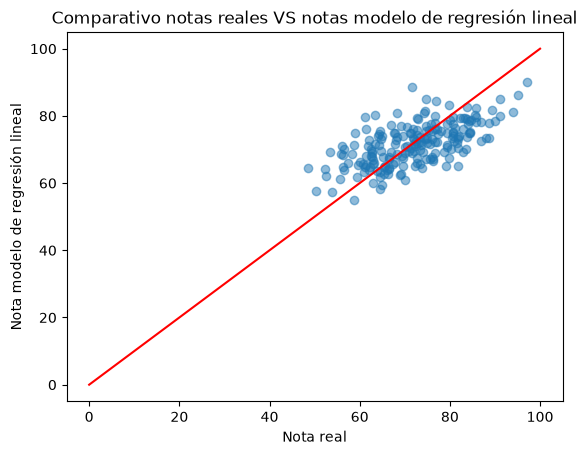

In [99]:
#Mediante el gráfico de dispersión, comparamos visualmente las notas reales frente a las calculadas a partir del modelo utilizado
plt.scatter(y_reg_test, predicciones_regresion, alpha=0.5)

plt.title("Comparativo notas reales VS notas modelo de regresión lineal")
plt.xlabel("Nota real")
plt.ylabel("Nota modelo de regresión lineal")

plt.plot([0, 100], [0, 100], color="red")

plt.show()

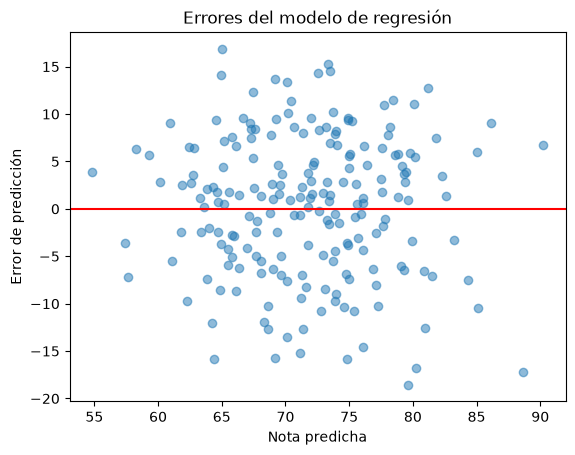

In [100]:
#Mediante el gráfico de dispersión, representamos el error del predicción del modelo frente a la nota predicha
plt.scatter(resultados_regresion["nota_predicha"], resultados_regresion["error"], alpha=0.5)

plt.title("Errores del modelo de regresión")
plt.xlabel("Nota predicha")
plt.ylabel("Error de predicción")

plt.axhline(y=0, color="red")

plt.show()

## 4. Entrenamiento y validación del modelo de clasificación

Utilizaremos una regresión logística para predecir si un estudiante aprueba (1) o suspende (0).

### 4.1 Entrenamiento y ejecución del modelo de clasificación

In [ ]:
#Importamos el modelo de clasificación
from sklearn.linear_model import LogisticRegression

#Creamos el modelo realizando un máximo de 1.000 iteraciones
modelo_clasificacion = LogisticRegression(max_iter=1000)

#Lanzamos el modelo de regresión logística con los datos de entrenamiento
modelo_clasificacion.fit(X_train_modelo, y_clas_train)

#Lanzamos el modelo de regresión logística para que realice la predicción (aprobado o suspenso) sobre los datos de prueba
predicciones_clasificacion = modelo_clasificacion.predict(X_test_modelo)

In [102]:
#Creamos un dataframe para comparar los resultados de la predicción del modelo de clasificación con los resultados reales
resultados_clasificacion = pd.DataFrame(index=y_clas_test.index)

resultados_clasificacion["aprobado_real"] = y_clas_test
resultados_clasificacion["aprobado_modelo"] = predicciones_clasificacion

resultados_clasificacion.head()

,aprobado_real,aprobado_modelo
168,1,1
929,0,1
269,1,1
750,1,1
184,0,1


### 4.2 Evaluación del modelo de clasificación

#### 4.2.1 Matriz de confusión
Comparamos los resultados reales con los predichos para contar los aciertos y los errores en aprobados y suspensos.

In [103]:
#Montamos una matriz de clasificación donde se puedeb comparar los aprobado y supensos reales verus los resultados del modelo de clasificación
matriz_clasificacion = pd.crosstab(
    resultados_clasificacion["aprobado_real"],
    resultados_clasificacion["aprobado_modelo"]
)

matriz_clasificacion

aprobado_modelo,0,1
aprobado_real,,
0,2,18
1,1,179


In [104]:
#Calculamos el porcentaje de acierto del modelo
aciertos_clasificacion = (
    resultados_clasificacion["aprobado_real"]
    == resultados_clasificacion["aprobado_modelo"]
)

aciertos_clasificacion_mean = aciertos_clasificacion.mean()

print("Porcentaje de acierto:", round(aciertos_clasificacion_mean * 100,2), "%")

Porcentaje de acierto: 90.5 %


#### 4.2.2 Métricas precision_score y recall_score
Aunque la media de aciertos del modelo está sobre el 90%, se observa que la detección de suspensos solo acierta en el 10% de las ocasiones. Analizamos los suspensos a partir de estas dos métricas.

In [105]:
#Importamos las dos métricas de precisión y recall para evaluar la detección de suspensos
from sklearn.metrics import precision_score, recall_score

#Esta métrica nos indica el porcentaje de suspensos reales sobre los suspensos definidos por el modelo
precision_suspensos = precision_score(
    y_clas_test,
    predicciones_clasificacion,
    pos_label=0
)
#Esta métrica nos indica el porcentaje de suspensos reales que el modelo ha sido capaz de detectar correctamente
recall_suspensos = recall_score(
    y_clas_test,
    predicciones_clasificacion,
    pos_label=0
)

print("Suspensos reales VS modelo (%):", round(precision_suspensos * 100,2))
print("Suspenso modelo VS reales (%):", round(recall_suspensos * 100,2))

Suspensos reales VS modelo (%): 66.67
Suspenso modelo VS reales (%): 10.0
